<a href="https://colab.research.google.com/github/sandyy221/244107020029_PemMes/blob/main/Jobsheet_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Praktikum 1

In [1]:
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt   # untuk membuat plot/visualisasi
import numpy as np                # untuk operasi array numerik

from sklearn.cluster import DBSCAN            # algoritma pembanding (density-based biasa)
from sklearn.datasets import make_blobs       # generator dataset sintetis berbentuk gumpalan (blob) Gaussian
import hdbscan                                # algoritma utama praktikum

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    # Jika tidak ada axes yang diberikan, buat figure baru
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))

    # Nilai default agar fungsi tetap bisa dipakai tanpa labels / probabilities
    # (np.ones -> semua titik dianggap satu cluster dengan probabilitas 1)
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])

    # Daftar label unik (termasuk -1 jika ada noise)
    unique_labels = set(labels)

    # Satu warna untuk tiap label unik, diambil merata dari colormap Spectral
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    # Dictionary: indeks titik -> probabilitas keanggotaan (dipakai untuk ukuran marker)
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        # Indeks semua titik yang berlabel k
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",             # noise = 'x', cluster = lingkaran
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                # noise ukuran tetap 4; cluster: makin besar probabilitas -> makin besar titik
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )

    # Jumlah cluster = jumlah label unik, dikurangi 1 jika ada noise (-1) karena noise bukan cluster
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

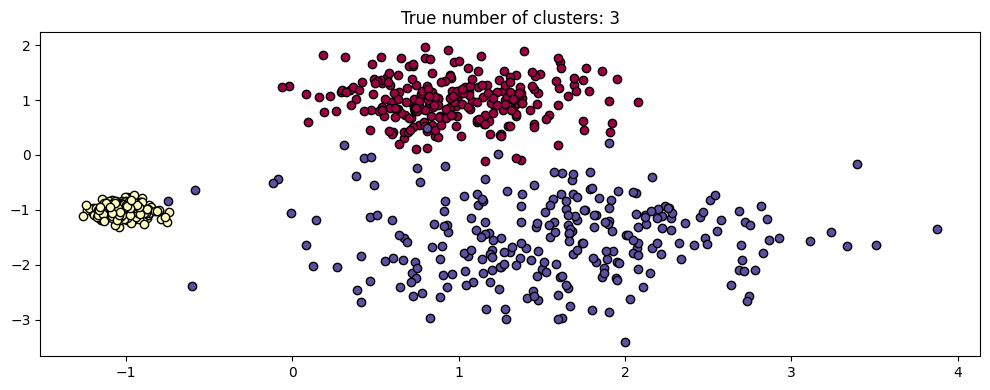

In [3]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)

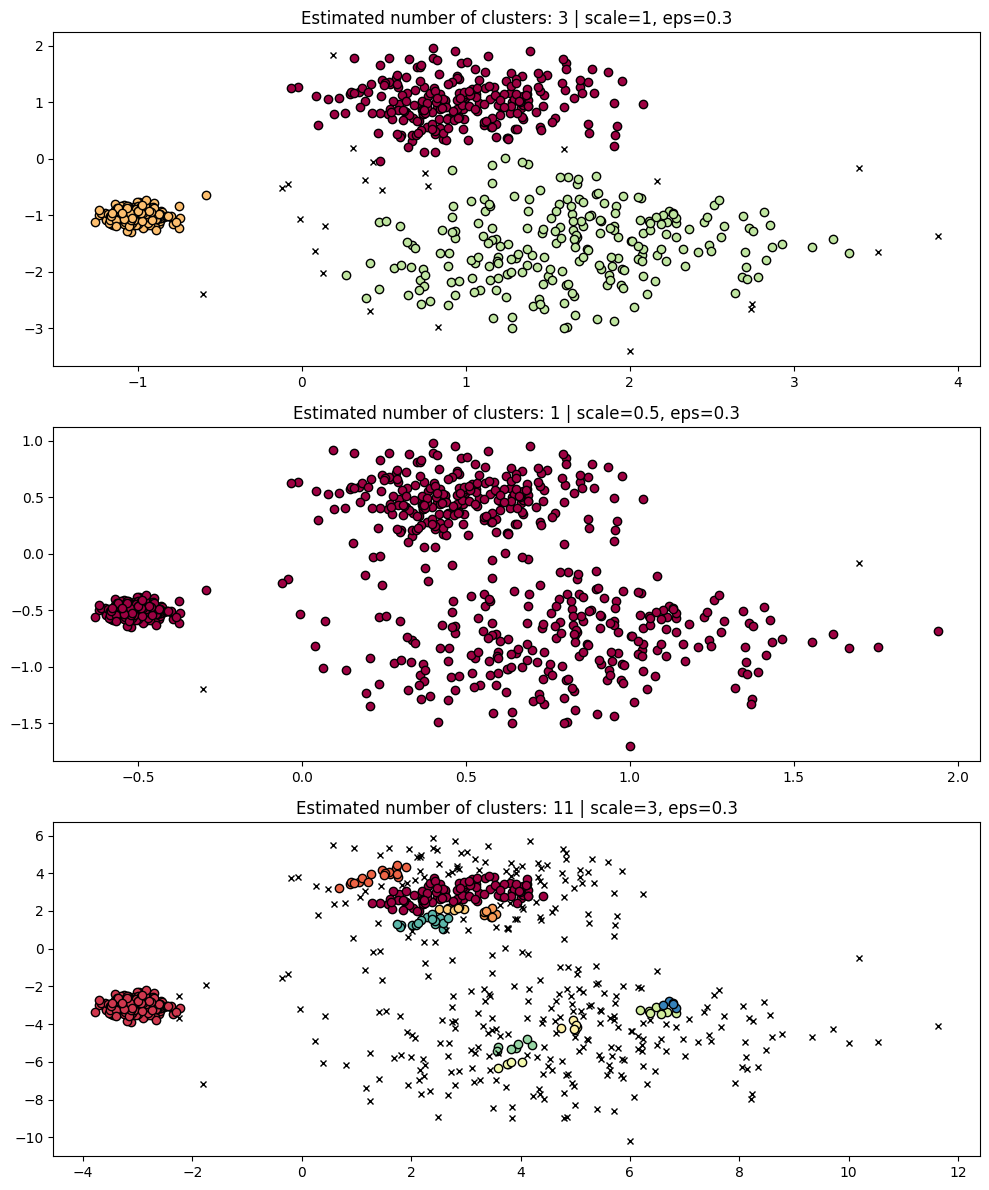

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)   # X dikalikan scale; eps tetap 0.3
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

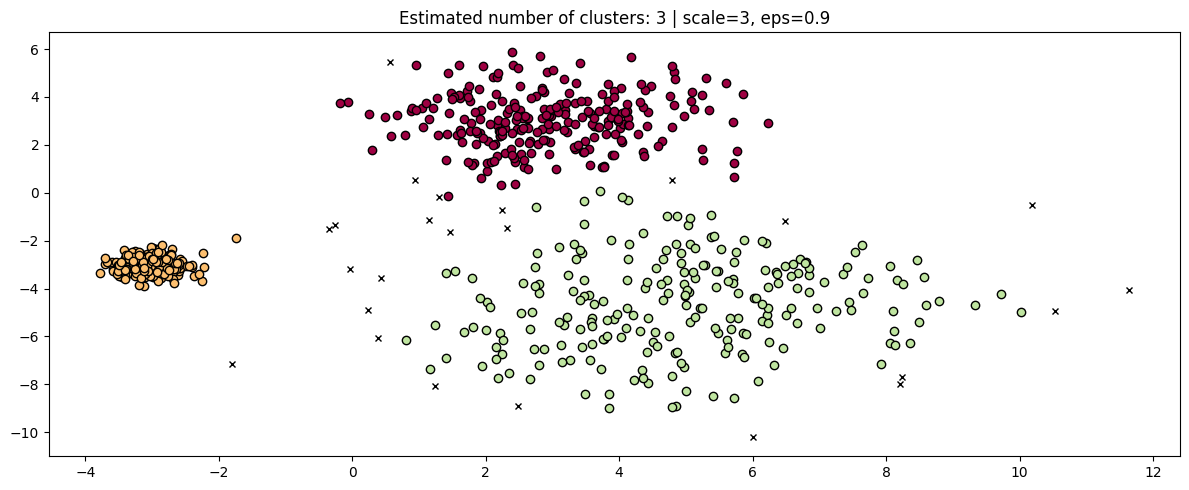

In [5]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)   # eps = 0.3 * 3 agar sebanding dengan skala data
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

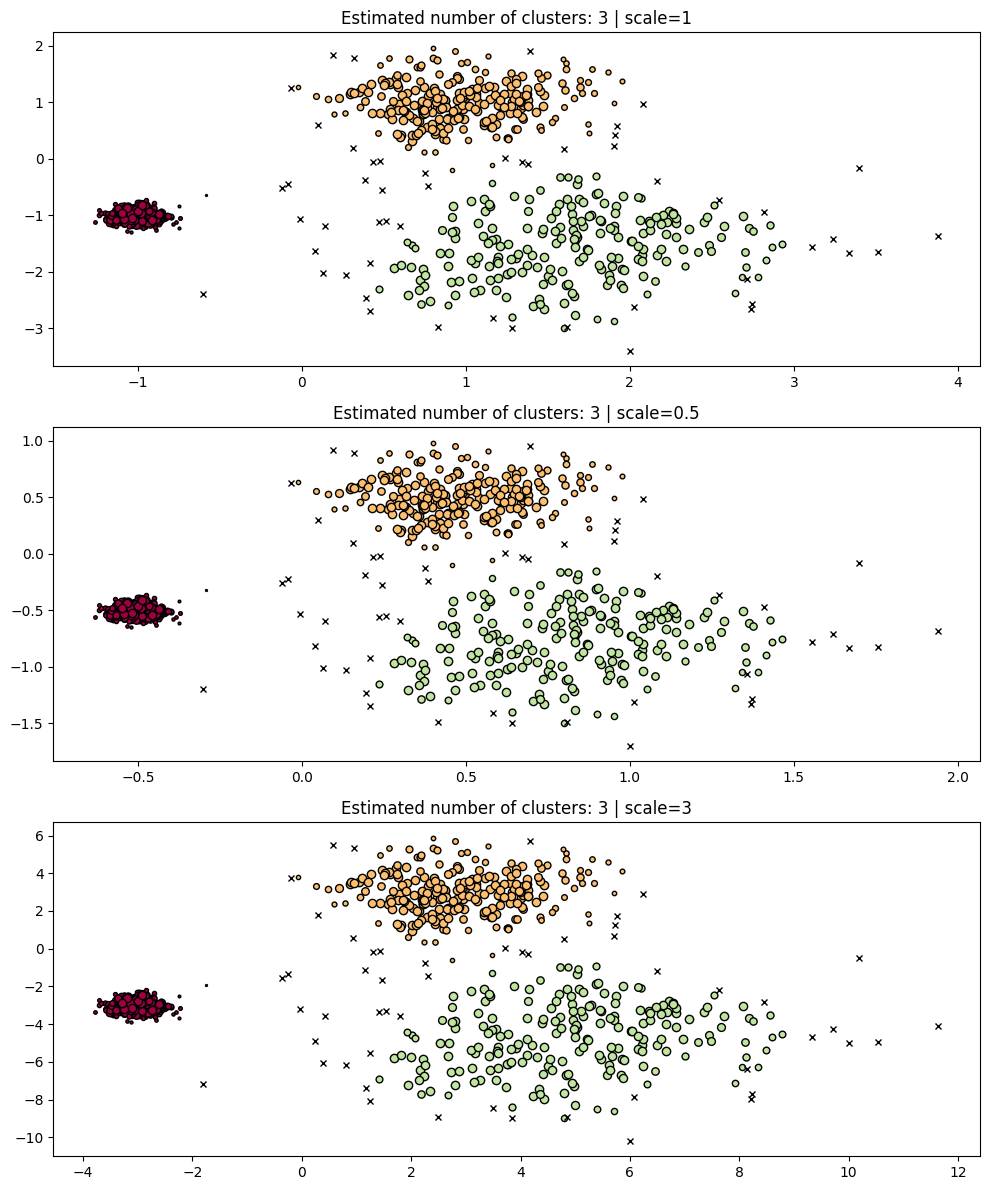

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()   # parameter default: min_cluster_size=5, min_samples=None (mengikuti min_cluster_size)
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

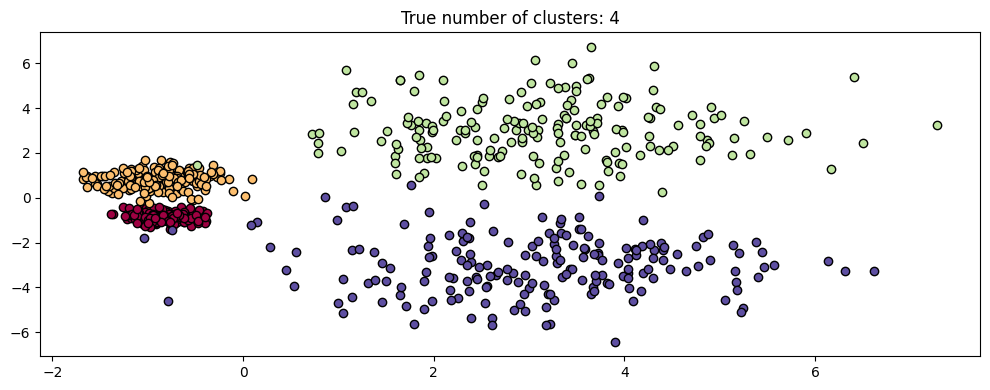

In [7]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

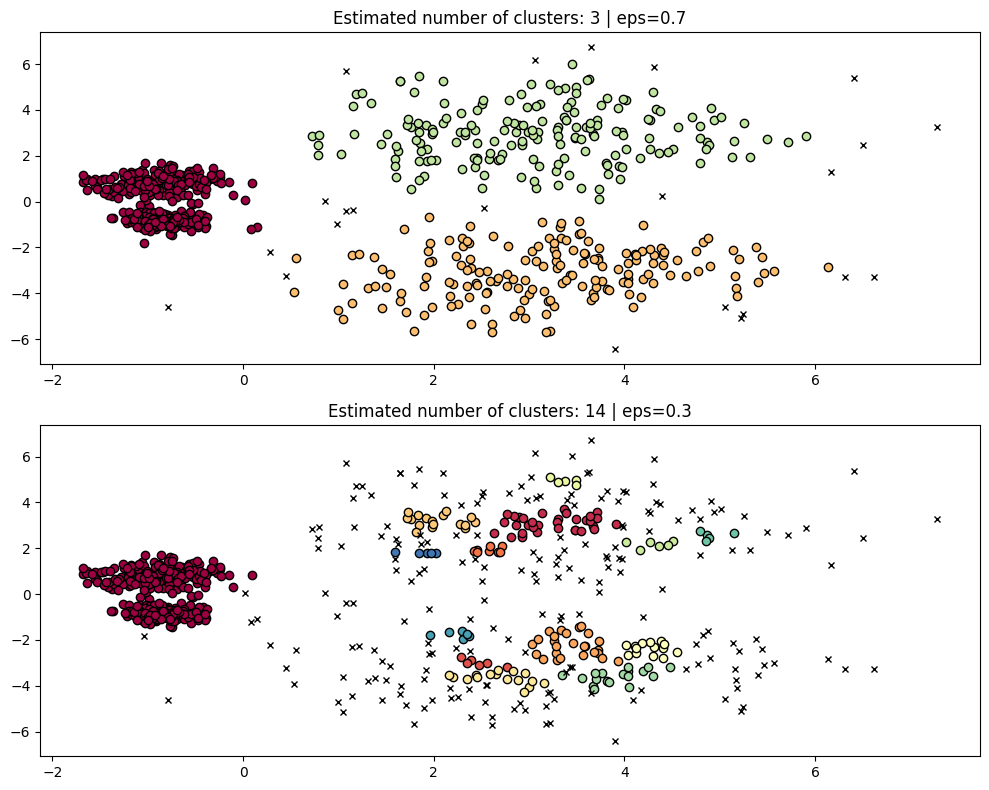

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)     # **params membongkar dict menjadi argumen: DBSCAN(eps=0.7)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

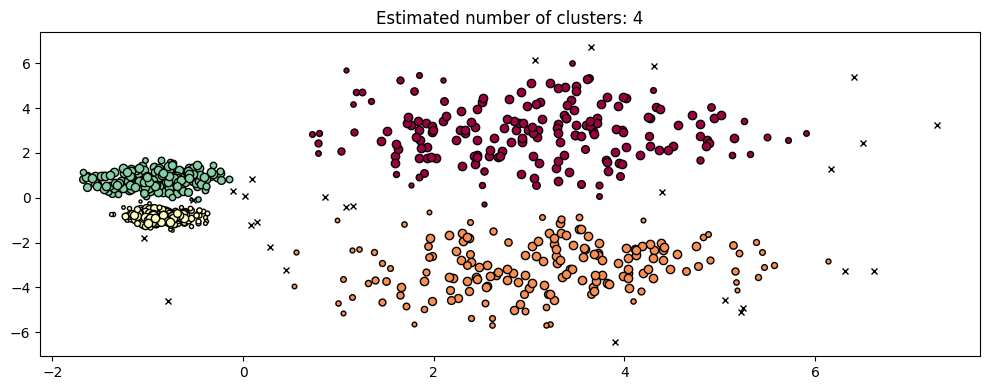

In [9]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)

In [10]:
def ringkas(nama, labels):
    n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    print(f"{nama:<28} cluster = {n_cluster:<3} noise = {n_noise}")

ringkas("Ground truth", labels_true)
ringkas("DBSCAN eps=0.7", DBSCAN(eps=0.7).fit(X).labels_)
ringkas("DBSCAN eps=0.3", DBSCAN(eps=0.3).fit(X).labels_)
ringkas("HDBSCAN (default)", hdb.labels_)

Ground truth                 cluster = 4   noise = 0
DBSCAN eps=0.7               cluster = 3   noise = 23
DBSCAN eps=0.3               cluster = 14  noise = 206
HDBSCAN (default)            cluster = 4   noise = 27


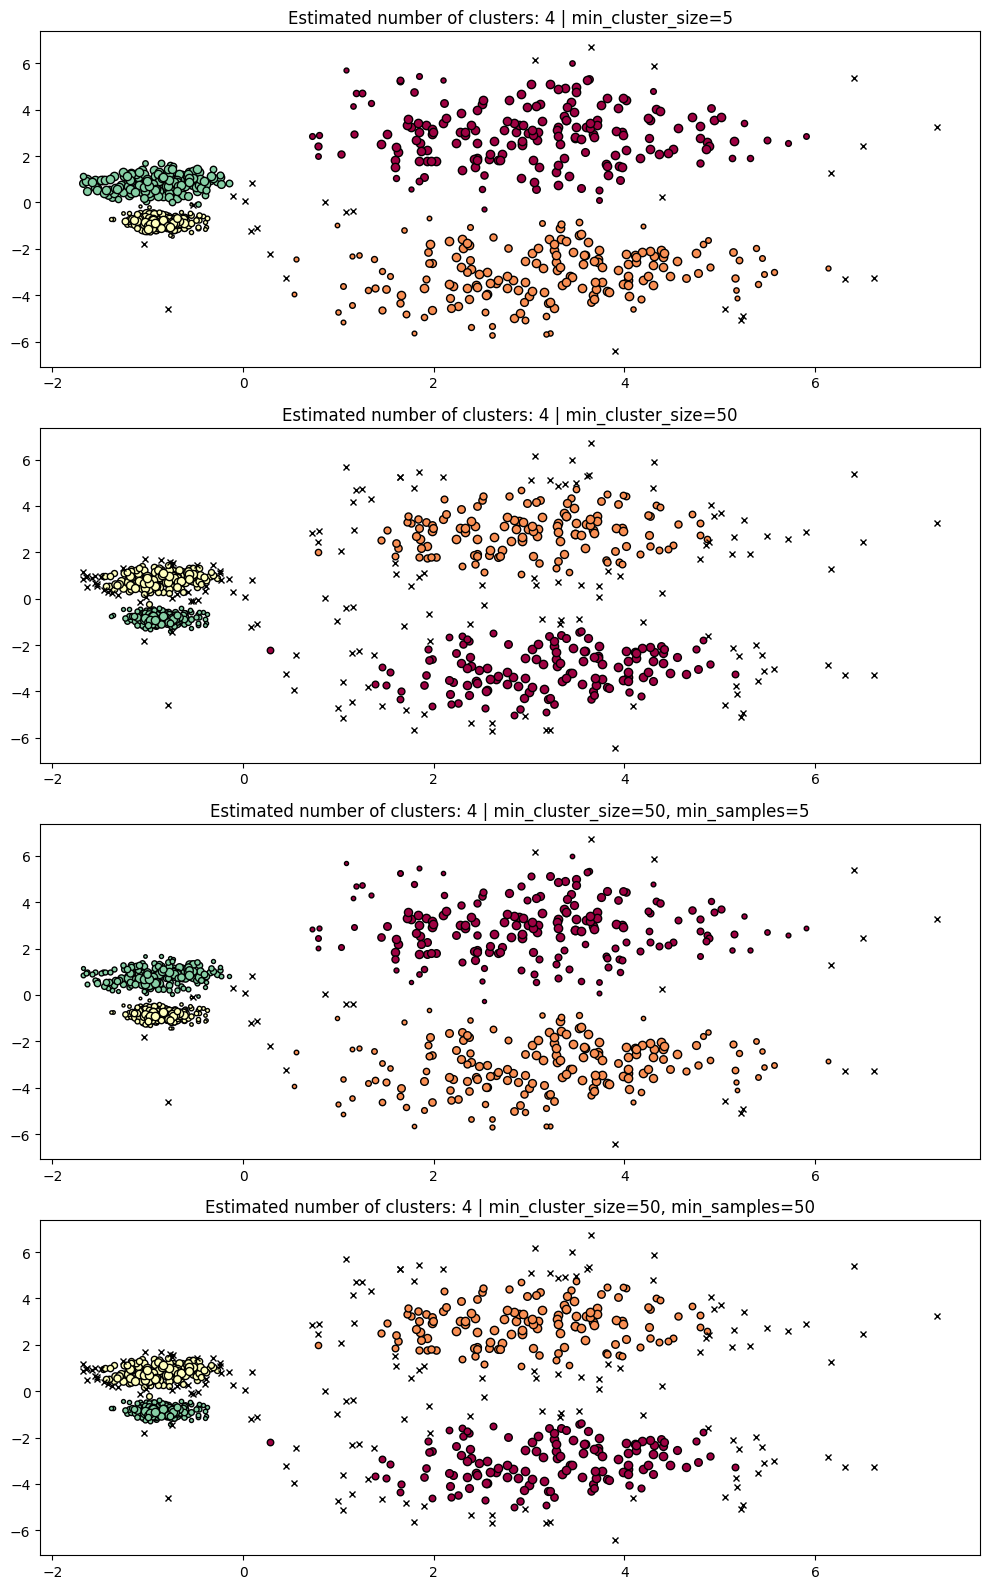

In [11]:
# --- Pengaruh min_cluster_size dan min_samples ---
konfigurasi = [
    {"min_cluster_size": 5},                      # default
    {"min_cluster_size": 50},                     # min_samples (None) ikut 50 -> noise bertambah
    {"min_cluster_size": 50, "min_samples": 5},   # min_samples dilonggarkan (5) -> noise kembali berkurang
    {"min_cluster_size": 50, "min_samples": 50},  # min_samples dieksplisitkan 50 -> sama dengan kasus kedua
]

fig, axes = plt.subplots(len(konfigurasi), 1, figsize=(10, 4 * len(konfigurasi)))
for ax, params in zip(axes, konfigurasi):
    h = hdbscan.HDBSCAN(**params).fit(X)
    plot(X, h.labels_, h.probabilities_, parameters=params, ax=ax)

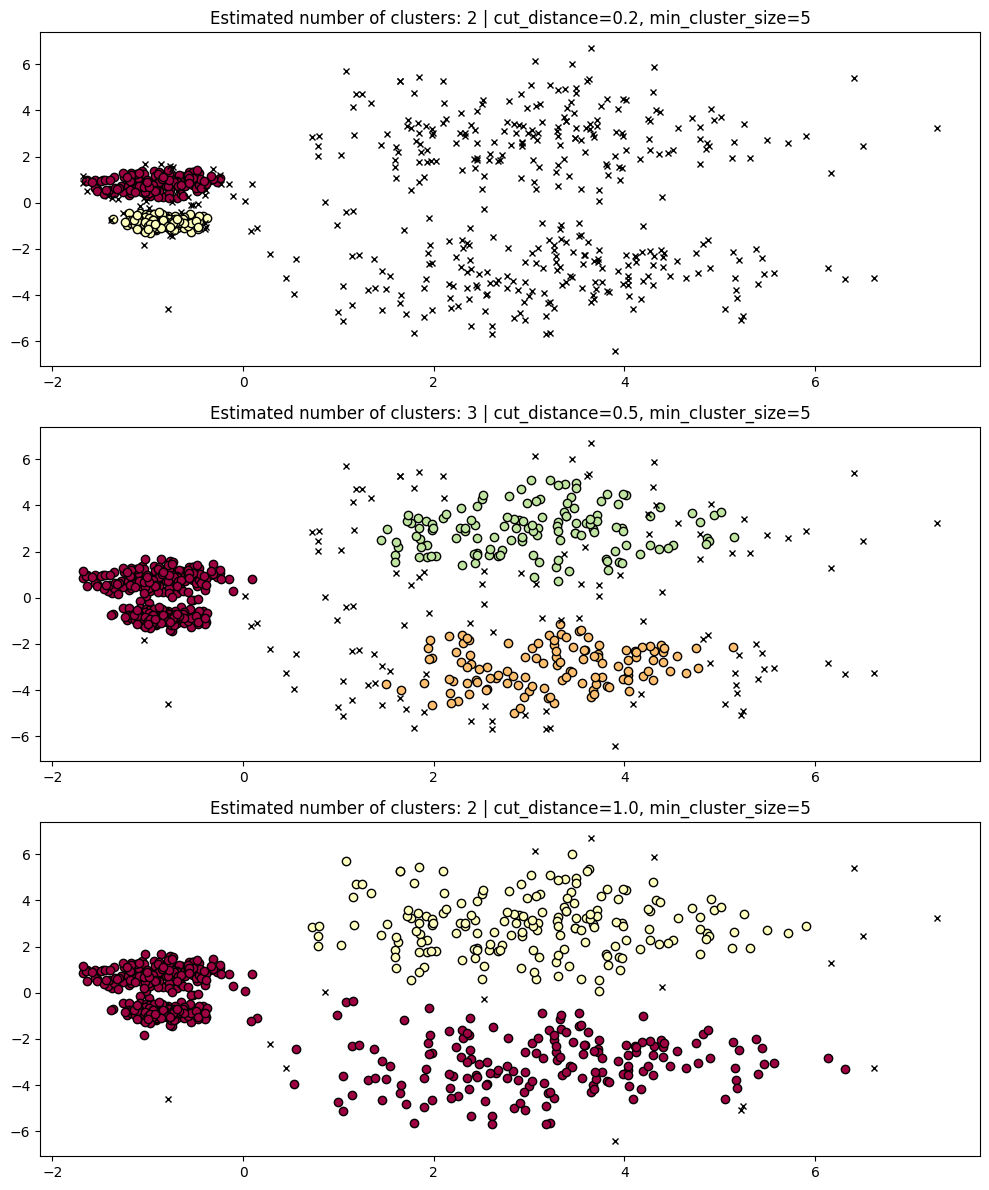

In [12]:
# --- Pengaruh cut_distance ---
# Hierarki cluster disimpan di atribut single_linkage_tree_.
# get_clusters() memotong pohon pada jarak tertentu (cut_distance) -> label gaya DBSCAN.
hdb = hdbscan.HDBSCAN(min_cluster_size=5).fit(X)

cut_values = [0.2, 0.5, 1.0]
fig, axes = plt.subplots(len(cut_values), 1, figsize=(10, 4 * len(cut_values)))
for ax, cut in zip(axes, cut_values):
    labels_cut = hdb.single_linkage_tree_.get_clusters(cut_distance=cut, min_cluster_size=5)
    plot(X, labels_cut, parameters={"cut_distance": cut, "min_cluster_size": 5}, ax=ax)

## Kesimpulan yang didapat

1. **DBSCAN sensitif terhadap skala.** Dengan eps tetap, hasil clustering berubah saat data diskalakan (Langkah 4). eps harus disesuaikan manual.
2. **HDBSCAN tidak memerlukan eps** dan hasilnya stabil pada skala data berbeda (Langkah 5).
3. **Pada data dengan kepadatan berbeda**, satu nilai eps DBSCAN tidak mampu memisahkan semua cluster sekaligus, sedangkan HDBSCAN beradaptasi dengan kepadatan tiap cluster (Langkah 6).
4. **Hyperparameter HDBSCAN** (min_cluster_size, min_samples, cut_distance) mengendalikan ukuran minimum cluster, tingkat konservatif terhadap noise, dan level pemotongan hierarki.

#Praktikum 2

In [ ]:
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt   # untuk membuat plot/visualisasi
import numpy as np                # untuk operasi array numerik

from sklearn.cluster import DBSCAN            # (tidak dipakai di praktikum ini; disertakan agar sama dengan Praktikum 1)
from sklearn.datasets import make_blobs       # generator dataset sintetis berbentuk gumpalan (blob) Gaussian
import hdbscan                                # algoritma utama praktikum

In [ ]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    # Jika tidak ada axes yang diberikan, buat figure baru
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))

    # Nilai default agar fungsi tetap bisa dipakai tanpa labels / probabilities
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])

    # Daftar label unik (termasuk -1 jika ada noise)
    unique_labels = set(labels)

    # Satu warna untuk tiap label unik, diambil merata dari colormap Spectral
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    # Dictionary: indeks titik -> probabilitas keanggotaan (dipakai untuk ukuran marker)
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        # Indeks semua titik yang berlabel k
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",             # noise = 'x', cluster = lingkaran
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                # noise ukuran tetap 4; cluster: makin besar probabilitas -> makin besar titik
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )

    # Jumlah cluster = label unik dikurangi 1 jika ada noise (-1), karena noise bukan cluster
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

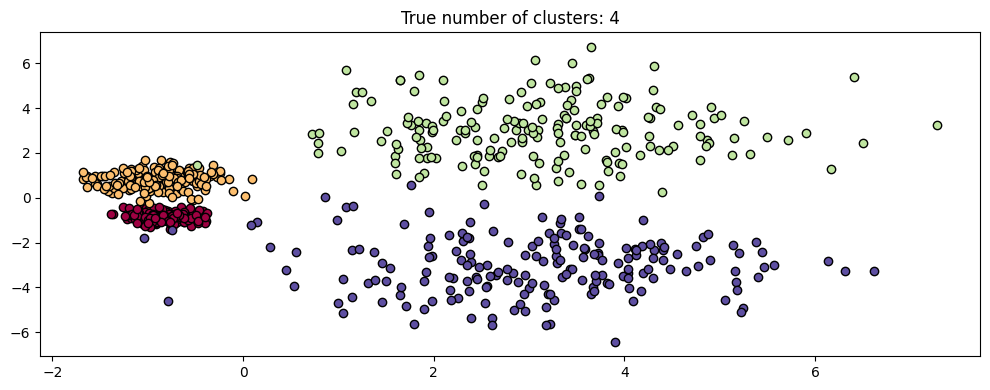

In [ ]:
# Dataset multi-scale (Langkah 6, Praktikum 1): 4 cluster dengan kepadatan berbeda
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

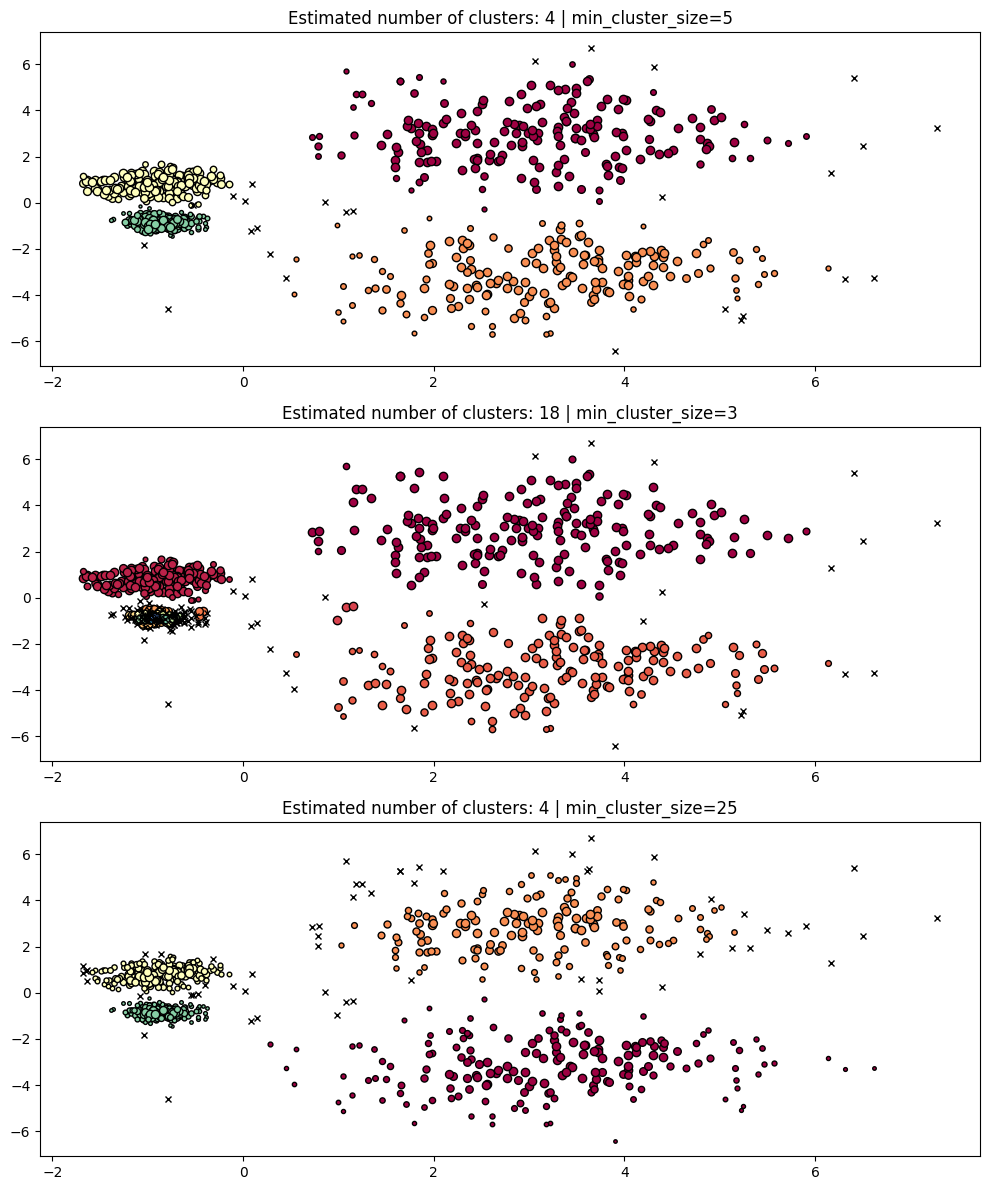

In [ ]:
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)       # **param -> HDBSCAN(min_cluster_size=...)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])   # param ikut ditampilkan di judul plot

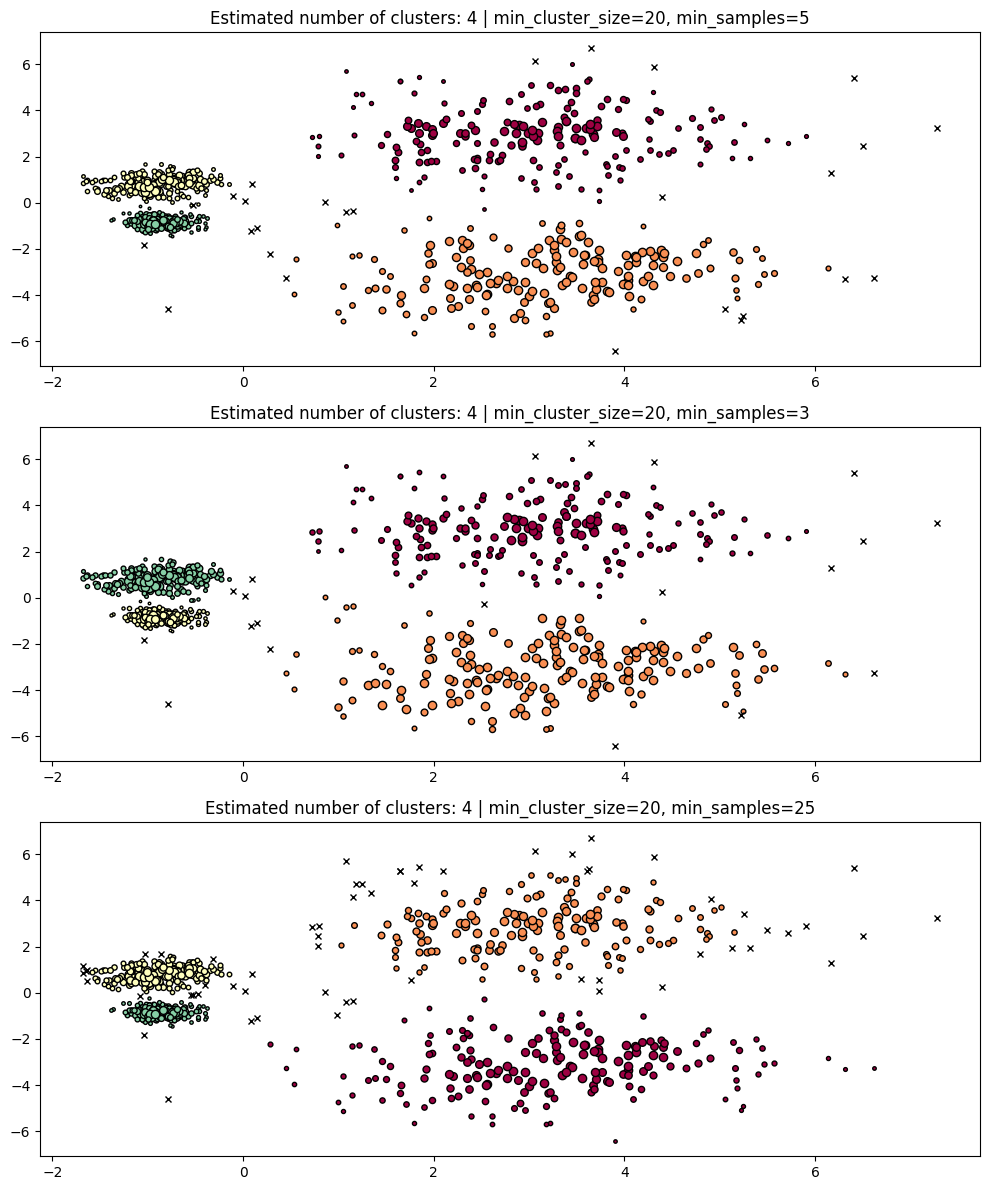

In [ ]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

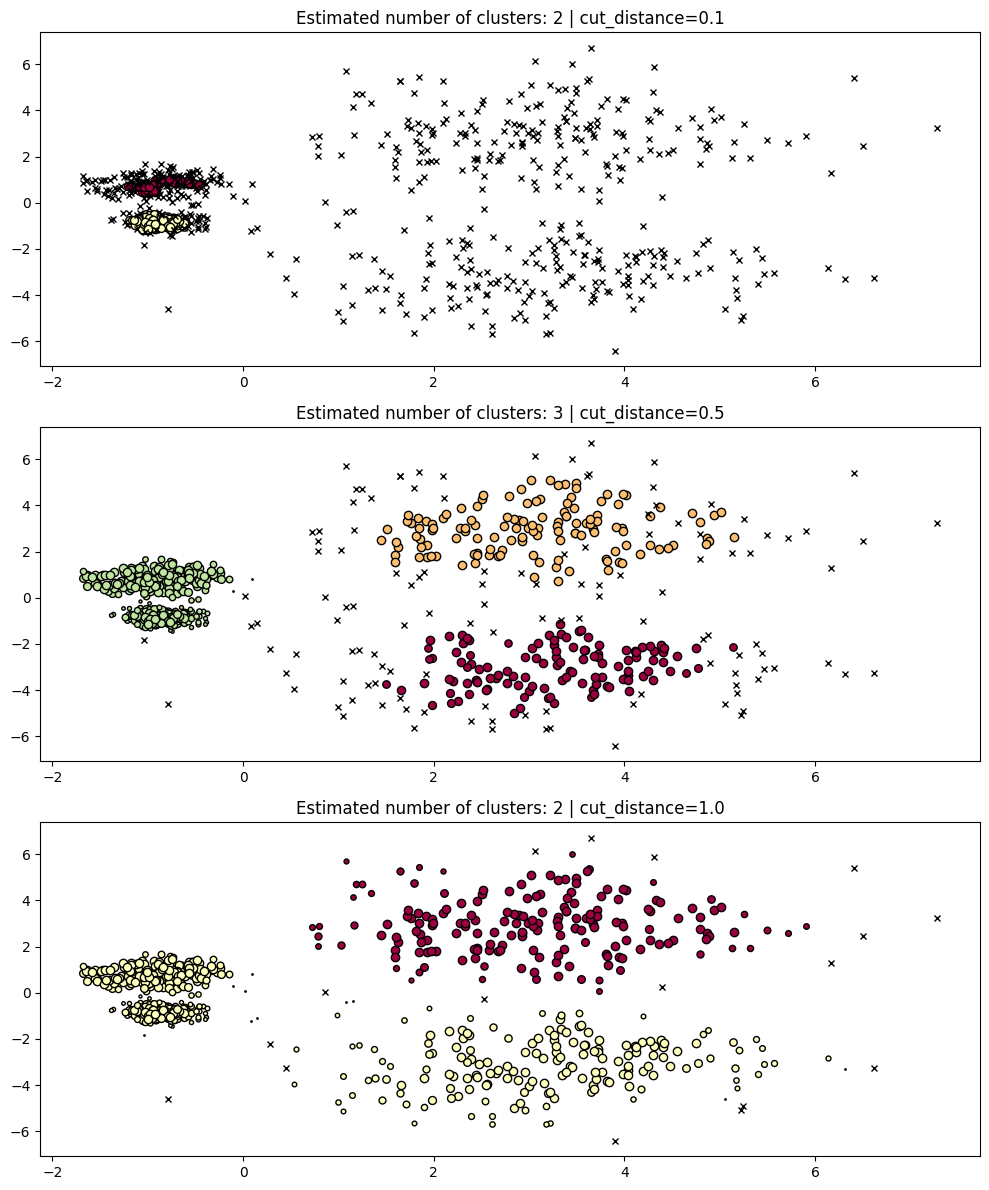

In [ ]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)     # model dilatih sekali; pemotongan dilakukan berkali-kali pada pohon yang sama
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)    # potong pohon pada jarak cut_distance
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

In [ ]:
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.5740100000784839


In [ ]:
from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.6436550644974441


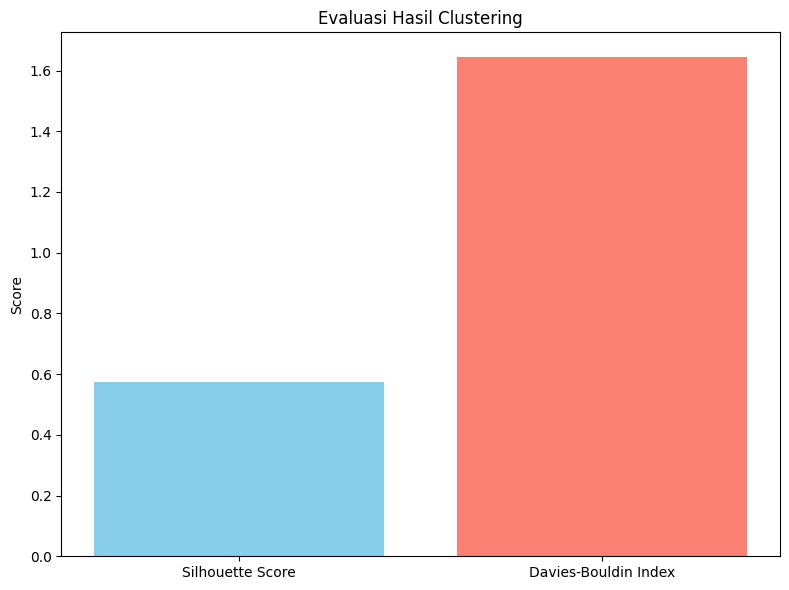

In [ ]:
# Misalnya kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

## Kesimpulan

1. **min_cluster_size** mengatur ukuran minimum cluster. Terlalu kecil menyebabkan fragmentasi (banyak cluster kecil); lebih besar membuat lebih banyak titik jarang menjadi noise (Langkah 7).
2. **min_samples** mengatur kekonservatifan terhadap noise: makin besar, makin banyak titik dianggap noise, sementara jumlah cluster relatif stabil (Langkah 8).
3. **cut_distance** memotong hierarki pada satu jarak tetap sehingga berperilaku seperti DBSCAN; satu jarak tunggal sulit memulihkan semua cluster pada data berkepadatan beragam (Langkah 9).
4. **Silhouette Score** (tinggi = baik) dan **Davies-Bouldin Index** (rendah = baik) memberi penilaian kuantitatif, tetapi harus dibaca bersama **jumlah noise** dan dengan memperhatikan apakah noise ikut dihitung (Langkah 10-12).
